# code_141 · Autoregressive likelihoods, invertible flows and energy sampling

**Book:** section 27.4. A self-contained generative-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_27_GUIDE.md), [run evidence](../CHAPTER_27_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_141).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3341;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3341


<a id="factorization-and-measure"></a>
 ## Three mechanisms need different evidence
 Ninety generated entities each supply ten correlated records: source60/development15/final15 entities. A binary regime, two continuous log sensor summaries and a count have a declared triangular generating structure. The autoregressive reference fits regime probability, conditional Gaussian first summary, Gaussian polynomial regression for the second summary and a Poisson count regression. The continuous flow and energy model fit only the two-summary marginal; their scores are not compared to the mixed joint likelihood. An own six-block affine-coupling flow gets1,200 Adam updates at0.003; development normalized log density chooses checkpoints every100updates. An own bounded-neural-plus-quadratic energy receives500 persistent-negative-phase updates at0.001, twenty Langevin steps per update, step0.04. Its checkpoint uses fixed development projected-distance panels. These are small native teaching implementations, not full MADE/RealNVP/EBM benchmark reproductions.


,model,final_projected_Wasserstein,generated_log_summary_correlation
0,Autoregressive,0.090432,0.690067
1,Coupling flow,0.127239,0.694231
2,Energy + Langevin,0.148079,0.646854


Separate mixed joint likelihood and continuous flow NLL: -3.064335796405325 1.6225286198905322 Energy chain initialization gap: 0.17359736337703863


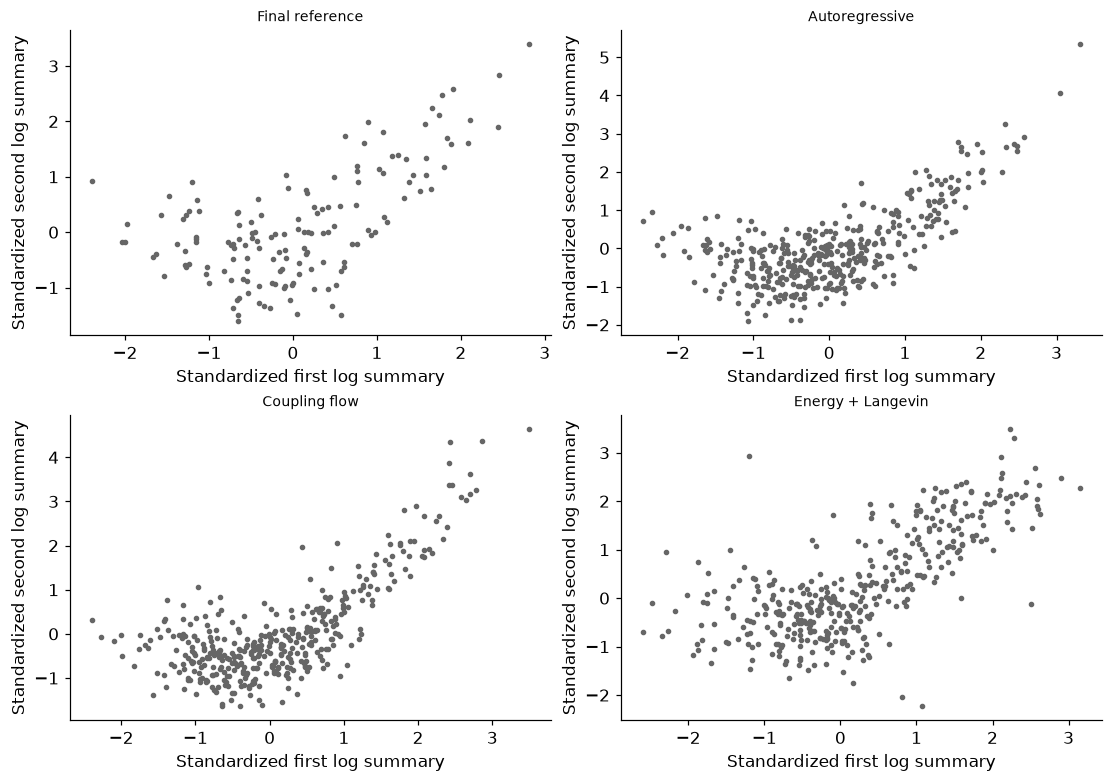

In [2]:
import copy
from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import norm,wasserstein_distance
B,R=90,10;entity=np.repeat(np.arange(B),R);c=rng.binomial(1,.25,B*R);a=rng.normal(-.6+1.2*c,.5,B*R)+rng.normal(0,.12,B)[entity];b=.4*c+.5*a+.35*a*a+rng.normal(0,.3,B*R);k=rng.poisson(np.exp(.2+.2*a+.25*b+.3*c));raw=np.column_stack([a,b]);source=entity<60;dev=(entity>=60)&(entity<75);final=entity>=75;prior=float(c[source].mean());first={v:(float(a[source&(c==v)].mean()),float(a[source&(c==v)].std())) for v in [0,1]}
def features(a,c):return np.column_stack([np.ones(len(a)),c,a,a*a])
design=features(a,c);coef=np.linalg.lstsq(design[source],b[source],rcond=None)[0];residual_sd=float(np.sqrt(np.mean((b[source]-design[source]@coef)**2)));count_design=np.column_stack([np.ones(len(a)),a,b,c]);ds=count_design[source];ks=k[source]
def poisson_objective(w):
    eta=ds@w;rate=np.exp(eta);return float(np.mean(rate-ks*eta+gammaln(ks+1))),ds.T@(rate-ks)/len(ds)
fit=minimize(poisson_objective,np.zeros(4),jac=True,method='BFGS',options={'gtol':1e-8});assert fit.success;count_coef=fit.x
def autoregressive(n):
    cc=rng.binomial(1,prior,n);aa=np.array([first[int(v)][0] for v in cc])+rng.normal(size=n)*np.array([first[int(v)][1] for v in cc]);bb=features(aa,cc)@coef+rng.normal(0,residual_sd,n);kk=rng.poisson(np.exp(np.column_stack([np.ones(n),aa,bb,cc])@count_coef));return np.column_stack([aa,bb]),cc,kk
ar,ar_c,ar_k=autoregressive(2000);joint_log=np.log(np.where(c[final],prior,1-prior))+np.array([norm.logpdf(av,*first[int(cv)]) for av,cv in zip(a[final],c[final])])+norm.logpdf(b[final],design[final]@coef,residual_sd);eta=count_design[final]@count_coef;joint_log+=k[final]*eta-np.exp(eta)-gammaln(k[final]+1)
assert set(np.unique(ar_c))<={0,1} and np.all(ar_k>=0) and np.all(ar_k==np.floor(ar_k))
center=raw[source].mean(0);spread=raw[source].std(0);z=(raw-center)/spread;X=torch.tensor(z);si=torch.tensor(np.flatnonzero(source));di=torch.tensor(np.flatnonzero(dev));fi=torch.tensor(np.flatnonzero(final));logjac=float(np.log(spread).sum())
class Coupling(nn.Module):
    def __init__(self,parity):super().__init__();self.register_buffer('mask',torch.tensor([float(parity),float(1-parity)]));self.net=nn.Sequential(nn.Linear(2,24),nn.Tanh(),nn.Linear(24,24),nn.Tanh(),nn.Linear(24,4))
    def transform(self,x,inverse=False):
        fixed=x*self.mask;shift,scale=self.net(fixed).chunk(2,1);shift=shift*(1-self.mask);scale=1.2*torch.tanh(scale)*(1-self.mask);out=fixed+(1-self.mask)*((x-shift)*torch.exp(-scale) if inverse else x*torch.exp(scale)+shift);return out,(-scale if inverse else scale).sum(1)
class Flow(nn.Module):
    def __init__(self):super().__init__();self.layers=nn.ModuleList([Coupling(j%2) for j in range(6)])
    def transform(self,x,inverse=False):
        ld=torch.zeros(len(x))
        for layer in reversed(self.layers) if inverse else self.layers:x,delta=layer.transform(x,inverse);ld=ld+delta
        return x,ld
    def log_prob(self,x):latent,ld=self.transform(x,True);return -.5*(latent**2+np.log(2*np.pi)).sum(1)+ld
flow=Flow();probe=X[si[:8]];latent,ld=flow.transform(probe,True);back,forward_ld=flow.transform(latent);torch.testing.assert_close(back,probe,atol=1e-12,rtol=1e-12);torch.testing.assert_close(ld+forward_ld,torch.zeros_like(ld),atol=1e-12,rtol=1e-12)
point=probe[0].clone().requires_grad_(True);J=torch.autograd.functional.jacobian(lambda q:flow.transform(q[None,:],True)[0][0],point);analytic=flow.transform(point[None,:],True)[1][0];torch.testing.assert_close(torch.linalg.slogdet(J)[1],analytic,atol=1e-10,rtol=1e-10)
optimizer=torch.optim.Adam(flow.parameters(),lr=.003);best=np.inf;flow_history=[]
for step in range(1200):
    ids=si[torch.tensor(rng.choice(len(si),128))];optimizer.zero_grad();loss=-flow.log_prob(X[ids]).mean();loss.backward();optimizer.step()
    if (step+1)%100==0:
        with torch.no_grad():score=float(-flow.log_prob(X[di]).mean())+logjac
        flow_history.append([step+1,score])
        if score<best:best=score;state=copy.deepcopy(flow.state_dict());best_step=step+1
flow.load_state_dict(state)
with torch.no_grad():flow_sample=flow.transform(torch.tensor(rng.normal(size=(2000,2))))[0].numpy();flow_nll=float(-flow.log_prob(X[fi]).mean())+logjac
class Energy(nn.Module):
    def __init__(self):super().__init__();self.net=nn.Sequential(nn.Linear(2,32),nn.Tanh(),nn.Linear(32,32),nn.Tanh(),nn.Linear(32,1))
    def forward(self,x):return self.net(x).squeeze(1)+.5*x.square().sum(1)
energy=Energy();eo=torch.optim.Adam(energy.parameters(),lr=.001)
def langevin(initial,steps,step_size,noise=None):
    x=initial.detach().clone()
    for j in range(steps):
        x.requires_grad_(True);gradient=torch.autograd.grad(energy(x).sum(),x)[0];epsilon=torch.randn_like(x) if noise is None else noise[j];x=(x-.5*step_size*gradient+np.sqrt(step_size)*epsilon).detach()
    return x
directions=np.column_stack([np.cos(np.arange(16)*np.pi/16),np.sin(np.arange(16)*np.pi/16)])
def distance(a,b):return float(np.mean([wasserstein_distance(a@v,b@v) for v in directions]))
negative=torch.tensor(rng.normal(size=(256,2)));eval_start=torch.tensor(rng.normal(size=(256,2)));eval_noise=torch.tensor(rng.normal(size=(150,256,2)));best=np.inf;energy_history=[]
for step in range(500):
    negative=langevin(negative,20,.04);ids=si[torch.tensor(rng.choice(len(si),128))];eo.zero_grad();er=energy(X[ids]);en=energy(negative);loss=er.mean()-en.mean()+.001*(er.square().mean()+en.square().mean());loss.backward();eo.step()
    if (step+1)%100==0:
        sample=langevin(eval_start,150,.04,eval_noise).numpy();score=distance(sample,z[dev]);energy_history.append([step+1,score,float(loss.detach())])
        if score<best:best=score;energy_state=copy.deepcopy(energy.state_dict());energy_step=step+1
energy.load_state_dict(energy_state);energy_sample=langevin(torch.tensor(rng.normal(size=(2000,2))),400,.04).numpy();mix_noise=torch.tensor(rng.normal(size=(400,512,2)));chain0=langevin(torch.zeros((512,2)),400,.04,mix_noise).numpy();chain3=langevin(torch.full((512,2),3.),400,.04,mix_noise).numpy();mixing_gap=float(np.linalg.norm(chain0.mean(0)-chain3.mean(0)));samples={'Autoregressive':(ar-center)/spread,'Coupling flow':flow_sample,'Energy + Langevin':energy_sample};rows=[{'model':name,'final_projected_Wasserstein':distance(sample,z[final]),'generated_log_summary_correlation':float(np.corrcoef(sample.T)[0,1])} for name,sample in samples.items()]
RESULTS.update(building_counts=[60,15,15],record_counts=[int(source.sum()),int(dev.sum()),int(final.sum())],mixed_autoregressive_final_mean_log_likelihood=float(joint_log.mean()),flow_final_continuous_negative_log_likelihood=flow_nll,flow_selected_update=best_step,flow_updates=1200,flow_parameters=sum(p.numel() for p in flow.parameters()),energy_selected_update=energy_step,energy_updates=500,energy_parameters=sum(p.numel() for p in energy.parameters()),energy_training_langevin_steps_per_update=20,energy_final_sampling_steps=400,energy_langevin_step_size=.04,energy_common_noise_initialization_mean_gap=mixing_gap,comparisons=rows,autoregressive_count_reference_mean=float(k[final].mean()),autoregressive_count_generated_mean=float(ar_k.mean()));display(pd.DataFrame(rows));print('Separate mixed joint likelihood and continuous flow NLL:',float(joint_log.mean()),flow_nll,'Energy chain initialization gap:',mixing_gap)
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,(name,sample) in zip(axes.ravel(),[('Final reference',z[final]),*samples.items()]):ax.scatter(sample[:400,0],sample[:400,1],s=7,color='.4');ax.set(xlabel='Standardized first log summary',ylabel='Standardized second log summary',title=name)
plt.show()


<a id="sampling-and-density-limits"></a>
 ## Inversion and a tractable Jacobian do not diagnose coverage
 The autoregressive sampler draws in its declared order, using observed earlier variables only when evaluating a joint density. Changing order requires refitting the factorization. The coupling flow has an analytic triangular log determinant and a fixed Gaussian base; round-trip and autograd-Jacobian checks test actual code before fitting. Source standardization contributes a continuous density Jacobian. The mixed joint score includes discrete regime/count probabilities; it cannot be ranked against a two-coordinate marginal score. The energy adds a quadratic tail to a bounded tanh network so the ideal density is normalizable, but its partition function is uncomputed. Persistent negatives and finite-step unadjusted Langevin draws are approximations. A common-noise pair of widely separated chain starts diagnoses residual initialization sensitivity; small distance on this probe cannot establish equilibrium or every-mode coverage.


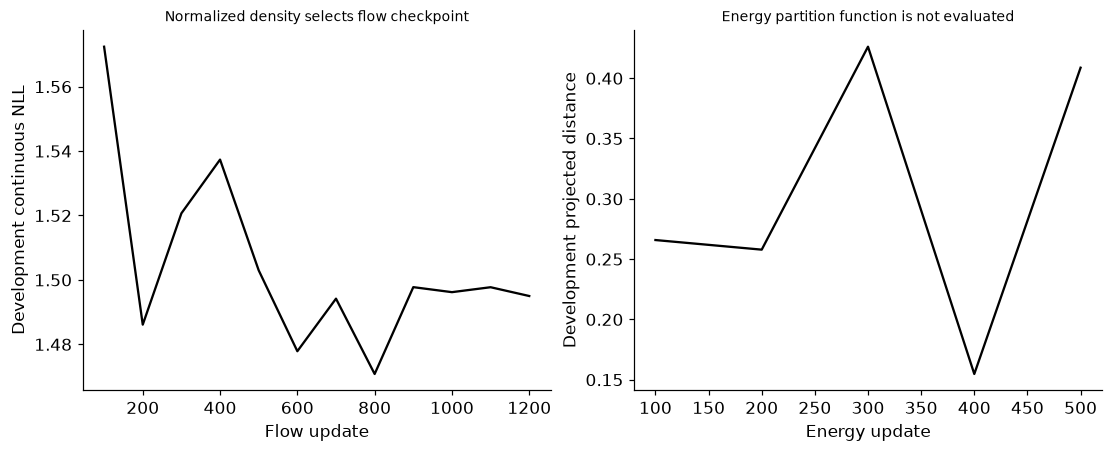

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));h=np.array(flow_history);axes[0].plot(h[:,0],h[:,1],color='black');axes[0].set(xlabel='Flow update',ylabel='Development continuous NLL',title='Normalized density selects flow checkpoint');h=np.array(energy_history);axes[1].plot(h[:,0],h[:,1],color='black');axes[1].set(xlabel='Energy update',ylabel='Development projected distance',title='Energy partition function is not evaluated');plt.show()
assert np.isfinite(flow_nll) and all(np.isfinite(r['final_projected_Wasserstein']) for r in rows)


In [4]:
summary={'example_id':'code_141','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['normalized mixed-type autoregressive factorization', 'native affine-coupling flow with inverse and Jacobian checks', 'native persistent-negative-phase energy learning', 'Langevin mixing and unnormalized score limits', 'independent reference assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["normalized mixed-type autoregressive factorization", "native affine-coupling flow with inverse and Jacobian checks", "native persistent-negative-phase energy learning", "Langevin mixing and unnormalized score limits", "independent reference assessment"], "elapsed_seconds": 4.572, "example_id": "code_141", "hardware": "Darwin arm64 CPU", "results": {"autoregressive_count_generated_mean": 1.5725, "autoregressive_count_reference_mean": 1.14, "building_counts": [60, 15, 15], "comparisons": [{"final_projected_Wasserstein": 0.09043162221452913, "generated_log_summary_correlation": 0.6900668708027331, "model": "Autoregressive"}, {"final_projected_Wasserstein": 0.12723915724322946, "generated_log_summary_correlation": 0.6942313459956098, "model": "Coupling flow"}, {"final_projected_Wasserstein": 0.14807850441131545, "generated_log_summary_correlation": 0.646854163652462, "model": "Energy + Langevin"}], "energy_common_noise_initialization_mean_